In [ ]:
# --------------------------------------------------------------------------
# 0. Libraries and Reproducibility
# --------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize
from scipy.stats import skew, spearmanr, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel

warnings.filterwarnings("ignore")
SEED = 42

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ---------------------------------------------------------------- 
# Load data
# ---------------------------------------------------------------- 
X = np.load('..\Function_3_Data\Week_11_Data/F3_Week_11_inputs.npy')
y = np.load('..\Function_3_Data\Week_11_Data/F3_Week_11_outputs.npy')
n, d = X.shape
N_INITIAL = 15
best = int(np.argmax(y))
x_best = X[best]
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[-1], 6)}, y = {y[-1]:.6f}")
print(f"best observed: row {best}, x = {np.round(x_best, 6)}, y = {y[best]:.6f}")

n = 25 (15 initial + 10 queried); newest x = [0.44653  0.572743 0.423725], y = -0.002265
best observed: row 24, x = [0.44653  0.572743 0.423725], y = -0.002265


Target Transformations (skew; gap between best and second-best value in std units)
  log   skew +0.60   gap 1.13
  sqrt  skew -0.88   gap 0.34
  raw   skew -2.64   gap 0.07




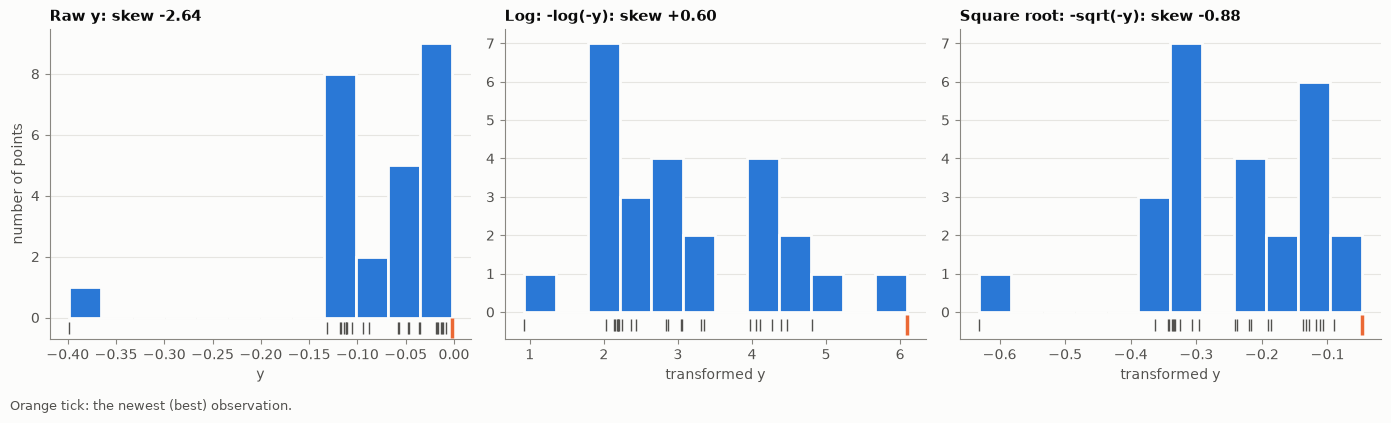

In [3]:
# ---------------------------------------------------------------- 
# Target transforms
# ---------------------------------------------------------------- 

TRANSFORMS = {
    "log": (lambda v: -np.log(-v), lambda m: -np.exp(-m)),
    "sqrt": (lambda v: -np.sqrt(-v), lambda m: -np.maximum(-m, 0) ** 2),
    "raw": (lambda v: v.copy(), lambda m: m),
}
print("=" * 100)
print("Target Transformations (skew; gap between best and second-best value in std units)")
print("=" * 100)
for name, (f, _) in TRANSFORMS.items():
    t = f(y)
    s = np.sort(t)
    print(f"  {name:5s} skew {skew(t):+.2f}   gap {(s[-1] - s[-2]) / t.std():.2f}")

print('\n')

# Fig 1: transforms
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, tname) in zip(axes, [("Raw y", "raw"), ("Log: -log(-y)", "log"), ("Square root: -sqrt(-y)", "sqrt")]):
    t = TRANSFORMS[tname][0](y)
    ax.hist(t, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(t, np.full(n, -0.35), "|", color=INK2, markersize=9, clip_on=False)
    ax.plot(t[best], -0.35, "|", color=ORANGE, markersize=14, markeredgewidth=2.5, clip_on=False)
    ax.set_title(f"{title}: skew {skew(t):+.2f}"); ax.set_ylim(bottom=-0.7); ax.grid(axis="x", visible=False)
    ax.set_xlabel("transformed y" if tname != "raw" else "y")
axes[0].set_ylabel("number of points")
fig.text(0.01, 0.01, "Orange tick: the newest (best) observation.", color=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

MODELS (LOO with hyperparameters fixed at the full fit)
  log-iso   ls=[0.075]  LOO RMSE/std=0.732  Spearman=0.506  raw-y RMSE on top 9=0.0051  LOO pred at best row=-0.0119
  log-ARD   ls=[1.00e+02 6.43e-01 9.50e-02]  LOO RMSE/std=0.585  Spearman=0.799  raw-y RMSE on top 9=0.0051  LOO pred at best row=-0.0131
  sqrt-iso  ls=[0.16]  LOO RMSE/std=0.815  Spearman=0.658  raw-y RMSE on top 9=0.0065  LOO pred at best row=-0.0109
  sqrt-ARD  ls=[100.      1.496   0.113]  LOO RMSE/std=0.769  Spearman=0.785  raw-y RMSE on top 9=0.0045  LOO pred at best row=-0.0115
  raw-iso   ls=[0.245]  LOO RMSE/std=0.920  Spearman=0.744  raw-y RMSE on top 9=0.0058  LOO pred at best row=-0.0090
  raw-ARD   ls=[100.      1.899   0.156]  LOO RMSE/std=1.079  Spearman=0.658  raw-y RMSE on top 9=0.0054  LOO pred at best row=-0.0099




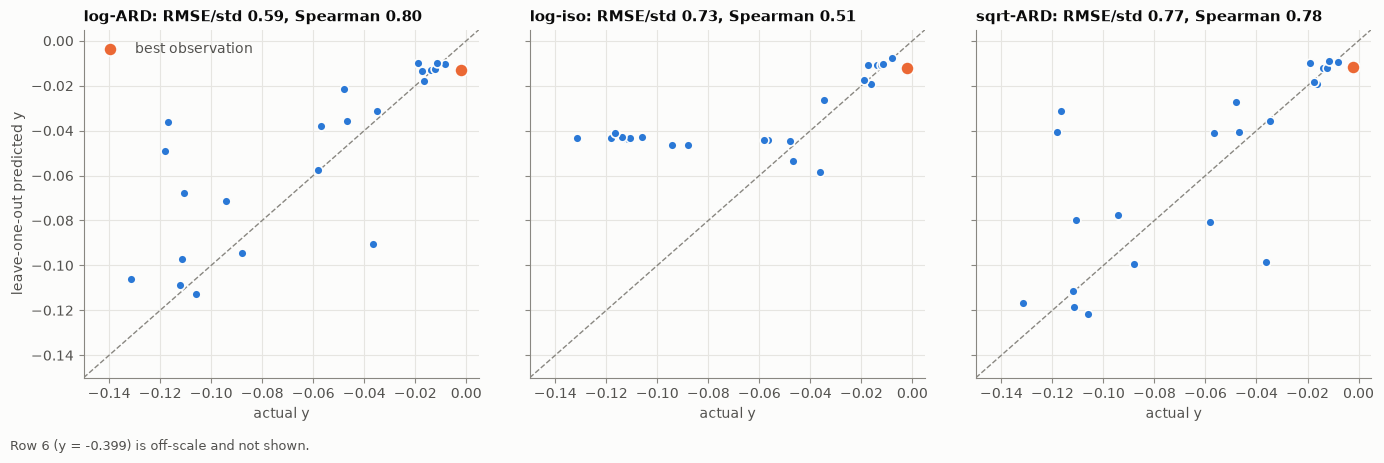

In [4]:
# ---------------------------------------------------------------- 
# GP models + LOO
# ---------------------------------------------------------------- 
def fit(t, ard):
    k = (ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-2, (1e-8, 3e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=20,
                                    random_state=SEED).fit(X, t)

top = np.argsort(-y)[:9]
models, loos = {}, {}
print('='*100)
print("MODELS (LOO with hyperparameters fixed at the full fit)")
print('='*100)
for tname, (f, back) in TRANSFORMS.items():
    t = f(y)
    for ard in (False, True):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(t, ard)
        mu = np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True).fit(X[keep], t[keep])
            mu[i] = g.predict(X[i:i + 1])[0]
        models[key], loos[key] = gp, mu
        yb = back(mu)
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:9s} ls={np.round(ls, 3)}  LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(t, mu)[0]:.3f}  raw-y RMSE on top 9={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.4f}  "
              f"LOO pred at best row={yb[best]:.4f}")

print('\n')

# Fig 2: LOO in raw y for three models
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, key in zip(axes, ["log-ARD", "log-iso", "sqrt-ARD"]):
    yb = TRANSFORMS[key.split('-')[0]][1](loos[key])
    t = TRANSFORMS[key.split('-')[0]][0](y)
    keep = np.arange(n) != 6
    lim = [-0.15, 0.005]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y[keep], yb[keep], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[best], yb[best], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="best observation")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{key}: RMSE/std {np.sqrt(np.mean((t - loos[key]) ** 2)) / t.std():.2f}, "
                 f"Spearman {spearmanr(t, loos[key])[0]:.2f}")
    ax.set_xlabel("actual y")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.text(0.01, 0.01, "Row 6 (y = -0.399) is off-scale and not shown.", color=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

BOWL MODEL on rows [3, 16, 17, 18, 20, 21, 22, 23, 24]
Floor e = 0.000033, Curvatures b = [3.99 0.89 5.38], Centre = [0.458182 0.646722 0.412835]
Residuals: [ 0.0006 -0.0023  0.0008 -0.0003  0.0015  0.002  -0.0001  0.0017 -0.0038]
Leave-one-out centres: min [0.363 0.567 0.405], max [0.479 0.653 0.416]




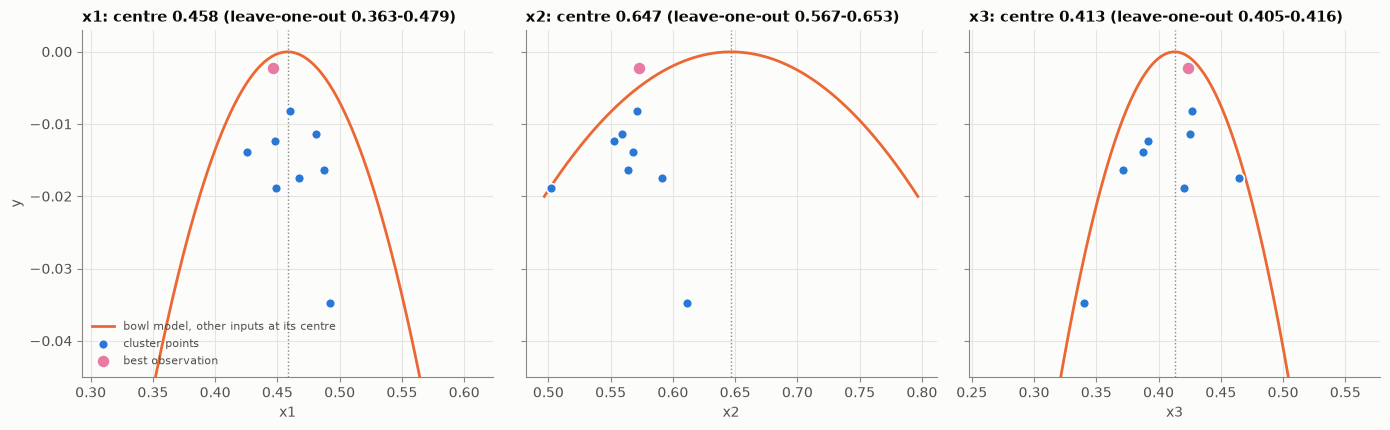

In [5]:
# ---------------------------------------------------------------- 
# Local bowl model
# -y = e + b1 (x1-c1)^2 + b2 (x2-c2)^2 + b3 (x3-c3)^2 on the cluster of best points
#-----------------------------------------------------------------

CL = [3, 16, 17, 18, 20, 21, 22, 23, 24]                                    # indeces of best points
LB, UB = [0, 0, 0, 0, 0, 0, 0], [1, 1e4, 1e4, 1e4, 1, 1, 1]
def bowl_res(p, Z, v):
    e, b1, b2, b3, c1, c2, c3 = p
    return e + b1 * (Z[:, 0] - c1) ** 2 + b2 * (Z[:, 1] - c2) ** 2 + b3 * (Z[:, 2] - c3) ** 2 - v
p_bowl = least_squares(bowl_res, [0.002, 1, 1, 1, 0.45, 0.57, 0.42], args=(X[CL], -y[CL]), bounds=(LB, UB)).x
centre = p_bowl[4:]
jack = np.array([least_squares(bowl_res, p_bowl, args=(X[[j for j in CL if j != i]], -y[[j for j in CL if j != i]]),
                               bounds=(LB, UB)).x[4:] for i in CL])
def bowl(Z):
    e, b1, b2, b3, c1, c2, c3 = p_bowl
    return -(e + b1 * (Z[:, 0] - c1) ** 2 + b2 * (Z[:, 1] - c2) ** 2 + b3 * (Z[:, 2] - c3) ** 2)
print('='*100)
print(f"BOWL MODEL on rows {CL}\nFloor e = {p_bowl[0]:.6f}, Curvatures b = {np.round(p_bowl[1:4], 2)}, " f"Centre = {np.round(centre, 6)}")
print(f"Residuals: {np.round(bowl(X[CL]) - y[CL], 4)}")
print(f"Leave-one-out centres: min {np.round(jack.min(0), 3)}, max {np.round(jack.max(0), 3)}")
print('='*100)
print('\n')

# Fig 3: cluster points vs each input, with the bowl through its centre
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for j, ax in enumerate(axes):
    xs = np.linspace(centre[j] - 0.15, centre[j] + 0.15, 200)
    Z = np.tile(centre, (len(xs), 1)); Z[:, j] = xs
    ax.plot(xs, bowl(Z), color=ORANGE, lw=2, label="bowl model, other inputs at its centre")
    ax.scatter(X[CL, j], y[CL], s=50, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="cluster points")
    ax.scatter(x_best[j], y[best], s=90, color=MAGENTA, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="best observation")
    ax.axvline(centre[j], color=MUTED, lw=1, ls=":")
    ax.set_xlabel(f"x{j + 1}"); ax.set_ylim(-0.045, 0.003)
    ax.set_title(f"x{j + 1}: centre {centre[j]:.3f} (leave-one-out {jack[:, j].min():.3f}-{jack[:, j].max():.3f})")
axes[0].set_ylabel("y")
axes[0].legend(frameon=False, loc="lower left", fontsize=8, labelcolor=INK2)
fig.tight_layout()

CANDIDATES: predicted y under each model (each GP's prediction at the best observed point in brackets)
Reference at best point: log-ARD=-0.0097  log-iso=-0.0073  sqrt-ARD=-0.0088  raw-iso=-0.0049  bowl=-0.0061
  A: EI, log-ARD (week-10 script)    x = (0.552058, 0.811755, 0.423072)  dist 0.261  log-ARD=-0.0088  log-iso=-0.0448  sqrt-ARD=-0.0024  raw-iso=-0.0959  bowl=-0.0600
  B: EI, log-isotropic               x = (0.436355, 0.575490, 0.428290)  dist 0.011  log-ARD=-0.0098  log-iso=-0.0075  sqrt-ARD=-0.0090  raw-iso=-0.0042  bowl=-0.0077
  C: bowl centre                     x = (0.458182, 0.646722, 0.412835)  dist 0.076  log-ARD=-0.0090  log-iso=-0.0195  sqrt-ARD=-0.0061  raw-iso=-0.0224  bowl=-0.0000
  D: half-step to bowl centre        x = (0.452356, 0.609733, 0.418280)  dist 0.038  log-ARD=-0.0092  log-iso=-0.0106  sqrt-ARD=-0.0072  raw-iso=-0.0098  bowl=-0.0015
  E: sqrt-ARD mean max (±0.1 box)    x = (0.423571, 0.672743, 0.419127)  dist 0.103  log-ARD=-0.0086  log-iso=-0.0262  sqr

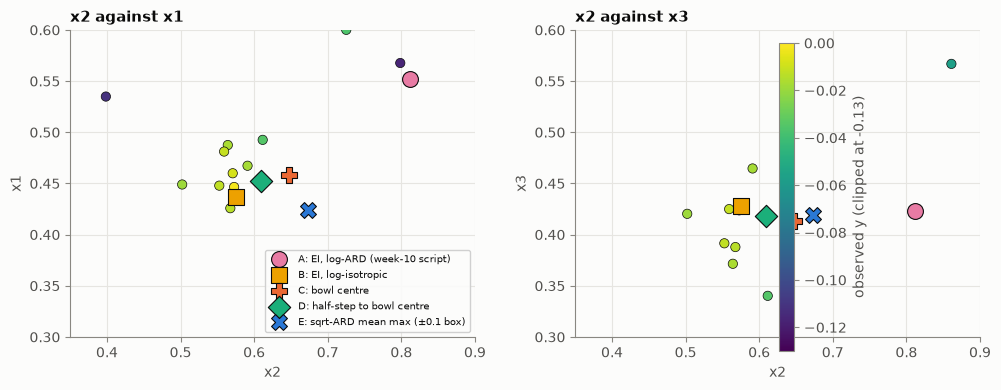

In [6]:
# ---------------------------------------------------------------- 
# Candidates
#-----------------------------------------------------------------

S = qmc.Sobol(d, seed=1).random(2 ** 14)
def box_argmax(fn, half):
    lo, hi = np.clip(x_best - half, 0, 1), np.clip(x_best + half, 0, 1)
    Z = lo + S * (hi - lo)
    x0 = Z[fn(Z).argmax()]
    r = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return r.x

cands = {
    "A: EI, log-ARD (week-10 script)": np.array([0.552058, 0.811755, 0.423072]),
    "B: EI, log-isotropic": np.array([0.436355, 0.575490, 0.428290]),
    "C: bowl centre": centre,
    "D: half-step to bowl centre": x_best + 0.5 * (centre - x_best),
    "E: sqrt-ARD mean max (±0.1 box)": box_argmax(lambda Z: models["sqrt-ARD"].predict(Z), 0.1),
}
PRED_KEYS = ["log-ARD", "log-iso", "sqrt-ARD", "raw-iso"]
print('='*100)
print("CANDIDATES: predicted y under each model (each GP's prediction at the best observed point in brackets)")
ref = {k: TRANSFORMS[k.split('-')[0]][1](models[k].predict(x_best[None]))[0] for k in PRED_KEYS}
print("Reference at best point: " + "  ".join(f"{k}={v:.4f}" for k, v in ref.items()) + f"  bowl={bowl(x_best[None])[0]:.4f}")
print('='*100)
cand_pred = {}
for name, xc in cands.items():
    preds = {k: TRANSFORMS[k.split('-')[0]][1](models[k].predict(xc[None]))[0] for k in PRED_KEYS}
    preds["bowl"] = bowl(xc[None])[0]
    cand_pred[name] = preds
    print(f"  {name:34s} x = ({xc[0]:.6f}, {xc[1]:.6f}, {xc[2]:.6f})  dist {np.linalg.norm(xc - x_best):.3f}  "
          + "  ".join(f"{k}={v:.4f}" for k, v in preds.items()))

print('\n')

# Fig 4: candidates in two projections
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
marks = [("o", MAGENTA), ("s", YELLOW), ("P", ORANGE), ("D", AQUA), ("X", BLUE)]
for ax, (i, j) in zip(axes, [(1, 0), (1, 2)]):
    sc = ax.scatter(X[:, i], X[:, j], c=y, cmap="viridis", vmin=-0.13, vmax=0, s=45, edgecolor=INK, linewidth=0.5, zorder=3)
    for (name, xc), (m_, c_) in zip(cands.items(), marks):
        ax.scatter(xc[i], xc[j], s=130, marker=m_, color=c_, edgecolor=INK, linewidth=0.8, zorder=5, label=name)
    ax.set_xlabel(f"x{i + 1}"); ax.set_ylabel(f"x{j + 1}")
    ax.set_xlim(0.35, 0.9); ax.set_ylim(0.3, 0.6)
axes[0].set_title("x2 against x1"); axes[1].set_title("x2 against x3")
fig.colorbar(sc, ax=axes, label="observed y (clipped at -0.13)")
axes[0].legend(frameon=True, fontsize=7.5, loc="lower right", framealpha=0.9)
fig.tight_layout()

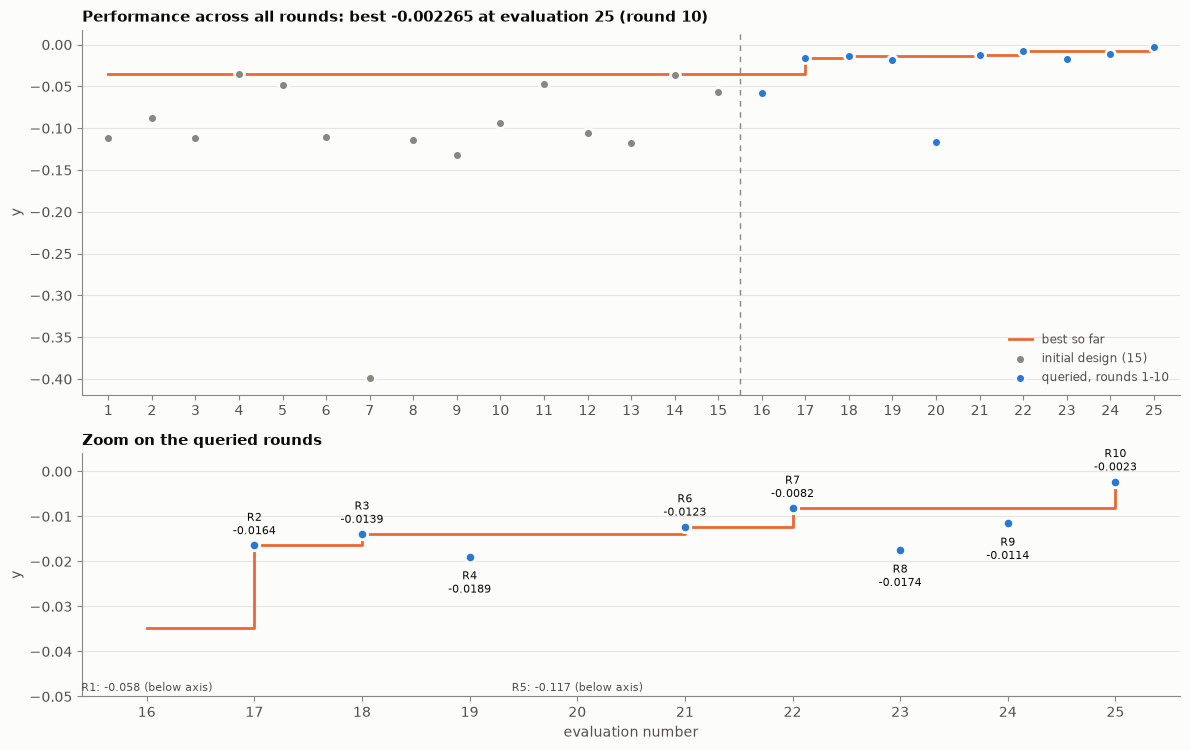

In [7]:
# Fig 5: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 7.6), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=2, label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=50, color=BLUE, edgecolor=SURFACE, linewidth=2, label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.6f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=ORANGE, lw=2, zorder=2)
az.scatter(idx[q], y[q], s=56, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
for i in q:
    if y[i] > -0.05:
        az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.4f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] else -26),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    else:
        az.annotate(f"R{i - N_INITIAL + 1}: {y[i]:.3f} (below axis)", (idx[i], -0.05), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
az.set_ylim(-0.05, 0.004); az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds")
fig.tight_layout()